# Phần 7 (Giai đoạn 6). Hệ thống Web Tư vấn Nguyện vọng (`app.py`, `run.bat`), Đánh giá Dashboard và Kết luận Dự án

Notebook cuối cùng trình bày **Giai đoạn 6** của dự án — bước đưa kết quả dự báo Học máy ra thành sản phẩm thực tiễn phục vụ học sinh và phụ huynh thông qua giao diện Web **`Streamlit`**, đồng thời đánh giá khách quan công cụ Dashboard và tổng kết toàn bộ đồ án (tương ứng **Chương IV** trong cấu trúc báo cáo).

**Nội dung cốt lõi cần nắm vững khi trình bày về Web App:**

    Giai đoạn 6. Ứng dụng Web Tư vấn Tuyển sinh & Tổng kết Đồ án
    ├── 7.1 Nhóm tạo Web App để làm gì? Đầu vào lấy từ đâu & Bên trong có gì?
    ├── 7.2 Bóc tách Phần Nạp dữ liệu Offline & Từ điển Tiếng Việt (load_data)
    ├── 7.3 Bóc tách Mục 1: Tư vấn Chọn trường & Xếp 3 Nhóm Nguyện Vọng (±0.5 điểm)
    ├── 7.4 Bóc tách Mục 2: Bảng Tra cứu Toàn cảnh 9 cột & Chênh lệch 2025 -> 2026
    ├── 7.5 Bóc tách Mục 3: Thẻ Thống kê & 2 Biểu đồ Phân bố Cạnh tranh 2026 (CI)
    └── 7.6 Phím tắt khởi chạy (run.bat), Đánh giá Dashboard Streamlit & Kết luận

---
### 7.1. Giải thích Dễ hiểu: Tạo App để làm gì, Đầu vào từ đâu và Trong App có gì?

#### 1. Chúng em xây dựng Web App (`app.py`) để làm gì?
- Kết quả đầu ra của mô hình AI ở Giai đoạn 5 là một tệp bảng dữ liệu (`results/predictions_2026.csv` gồm **216 chương trình Công nghệ** với các mã viết tắt như `BKA`, `QHI`, `SE_CYBER`). Nếu giữ nguyên dưới dạng tệp CSV hoặc dòng lệnh Python, học sinh lớp 12 và phụ huynh không thể tự lọc tổ hợp môn hay biết điểm thi của mình đang cao hay thấp hơn ngưỡng dự báo bao nhiêu.
- Do đó, nhóm xây dựng ứng dụng Web bằng thư viện **`Streamlit`** nhằm chuyển hóa kết quả AI thành **công cụ hỗ trợ ra quyết định tức thời**: thí sinh chỉ cần nhập điểm và chọn khối thi, hệ thống tự động tính khoảng cách điểm và gợi ý chiến lược đặt nguyện vọng hợp lý.

#### 2. Đầu vào (`Input`) của Web App lấy từ đâu?
Hệ thống nhận **2 nhóm đầu vào** tách biệt rất rõ ràng:

| Nhóm đầu vào | Nguồn cung cấp cụ thể | Vai trò trong `app.py` |
|---|---|---|
| **A. Đầu vào Dữ liệu Hệ thống (Đọc Offline 100%)** | 1. Tệp `results/predictions_2026.csv` (từ Bước 5)<br>2. Tệp `results/school_mapping.json` (từ Bước 4) | Cung cấp điểm chuẩn 2025, điểm dự báo 2026, chỉ tiêu THPT, chỉ số cạnh tranh CI, mức cạnh tranh và tên tiếng Việt của các trường ĐH mà **không cần kết nối lại SQL hay chạy lại AI** (tránh rủi ro treo máy khi bảo vệ). |
| **B. Đầu vào Tương tác từ Thí sinh** | 1. Điểm xét tuyển `user_score` (`0.0 – 30.0`)<br>2. Khối thi `user_block` (`A00`, `A01`, `D01`, `X06`...)<br>3. Bộ lọc phụ: Trường ĐH, Từ khóa ngành, Phân nhóm Công nghệ, Mức độ cạnh tranh | Giúp cá nhân hóa danh sách gợi ý theo đúng năng lực điểm số và sở thích ngành nghề của từng học sinh. |

#### 3. Bên trong Web App có những khu vực chức năng nào?
Giao diện `app.py` được thiết kế tối giản, nghiêm túc theo bố cục **3 khu vực từ trên xuống dưới**:
1. **Mục 1 — Tư vấn Chọn trường & Xếp Nguyện vọng:** Dựa trên độ chênh lệch giữa điểm thí sinh và điểm dự báo 2026 để tự động chia các ngành phù hợp vào 3 thanh Tab: **`Nhóm An Toàn`** ($\ge +0,5$ điểm), **`Nhóm Vừa Sức`** ($\pm 0,5$ điểm) và **`Nhóm Thử Thách`** ($-2,0$ đến $-0,5$ điểm).
2. **Mục 2 — Bảng Tra cứu Toàn cảnh Khối Công nghệ 2026:** Hỗ trợ 3 bộ lọc đa chọn ngang hàng (Trường ĐH × Phân nhóm Công nghệ × Mức độ cạnh tranh), hiển thị bảng 9 cột đối chiếu trực tiếp `Điểm Chuẩn 2025` với `Dự Báo 2026` và `Mức Tăng/Giảm`.
3. **Mục 3 — Thống kê & Biểu đồ Phân bố:** Tổng hợp 7 thẻ chỉ số nhanh (`st.metric`) về tỷ lệ 4 bậc cạnh tranh (theo Chỉ số CI: Rất cao, Cao, Trung bình, Thấp), số ngành tăng/giảm/ổn định điểm và 2 biểu đồ cột tương tác (`px.histogram`).

---
### 7.2. Bóc tách Phần Nạp Dữ liệu & Từ điển Tiếng Việt trong `app.py`

**Đoạn code nhỏ 1 (Phần 1 & Phần 3.1 trong `app.py`) — Khai báo thư viện, xử lý đường dẫn chạy độc lập và từ điển chuyển đổi mã 5 phân nhóm Công nghệ sang tên tiếng Việt dễ hiểu:**

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == 'báo cáo dự án':
    os.chdir('..')
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

import json
import pandas as pd
import matplotlib.pyplot as plt

TEN_NHOM_CONG_NGHE = {
    'AI_DATA': 'AI & Khoa học dữ liệu',
    'SE_CYBER': 'CNTT, Phần mềm & An toàn thông tin',
    'CHIP_IOT_HW': 'Vi mạch, IoT & Điện tử viễn thông',
    'AUTO_ELEC': 'Tự động hóa, Robot & Kỹ thuật điện',
    'MECH_AUTO_TECH': 'Kỹ thuật Ô tô, Cơ khí & Công nghệ'
}
print(f"Đã nạp từ điển hiển thị cho {len(TEN_NHOM_CONG_NGHE)} phân nhóm Công nghệ.")

Đã nạp từ điển hiển thị cho 5 phân nhóm Công nghệ.

**Đoạn code nhỏ 2 (Hàm phụ 1: `load_data` trong `app.py`) — Đọc tệp dự báo `results/predictions_2026.csv` và ghép tên trường tiếng Việt từ `results/school_mapping.json`:**

In [2]:
def load_data():
    df = pd.read_csv('results/predictions_2026.csv')
    with open('results/school_mapping.json', 'r', encoding='utf-8') as f:
        tu_dien_truong = json.load(f)
    df['ten_truong'] = df['ma_truong'].map(tu_dien_truong).fillna(df['ma_truong'])
    df['truong_display'] = df['ma_truong'] + " - " + df['ten_truong']
    df['nhom_nganh_display'] = df['ma_nganh_chuan'].map(TEN_NHOM_CONG_NGHE).fillna(df['ma_nganh_chuan'])
    return df

df = load_data()
print(f"Tổng số chương trình đào tạo nạp vào App: {len(df)} dòng | Số trường ĐH: {df['ma_truong'].nunique()} trường")
print(df[['truong_display', 'chuong_trinh_dao_tao', 'nhom_nganh_display', 'diem_chuan_du_bao']].head(5).to_string(index=False))

Tổng số chương trình đào tạo nạp vào App: 216 dòng | Số trường ĐH: 21 trường
                truong_display                                  chuong_trinh_dao_tao                 nhom_nganh_display  diem_chuan_du_bao
BKA - Đại học Bách khoa Hà Nội An toàn không gian số - Cyber Security (CT Tiên tiến) CNTT, Phần mềm & An toàn thông tin              28.03
BKA - Đại học Bách khoa Hà Nội                               CNTT: Khoa học Máy tính              AI & Khoa học dữ liệu              28.18
BKA - Đại học Bách khoa Hà Nội                               CNTT: Kỹ thuật Máy tính  Vi mạch, IoT & Điện tử viễn thông              28.59
BKA - Đại học Bách khoa Hà Nội                      Công nghệ thông tin (Global ICT) CNTT, Phần mềm & An toàn thông tin              28.02
BKA - Đại học Bách khoa Hà Nội                     Công nghệ thông tin (Việt - Nhật) CNTT, Phần mềm & An toàn thông tin              27.63

**Nhận xét và Đánh giá bảng dữ liệu nạp vào Web App (`load_data`):**
- Toàn bộ **216 chương trình đào tạo của 21 trường Đại học** từ tệp `results/predictions_2026.csv` đã được ghép nối hoàn chỉnh với từ điển `school_mapping.json` để hiển thị tên trường tiếng Việt đầy đủ (`BKA - Đại học Bách khoa Hà Nội`) cùng tên phân nhóm tiếng Việt trực quan, sẵn sàng phục vụ bộ lọc giao diện mà không cần truy vấn lại SQL Server.

**Đoạn code nhỏ 3 (Hàm phụ 2 & 3 trong `app.py`) — Hai hàm định dạng điểm số 2 chữ số thập phân và tự động gắn dấu `+`/`-` cho cột chênh lệch:**

In [3]:
def dinh_dang_diem(so_diem):
    return f"{so_diem:.2f}"

def dinh_dang_chenh_lech(so_chenh_lech):
    if so_chenh_lech > 0:
        return f"+{so_chenh_lech:.2f}"
    else:
        return f"{so_chenh_lech:.2f}"

print("Ví dụ định dạng hiển thị trên bảng Web:")
print("  Điểm dự báo 27.5      ->", dinh_dang_diem(27.5))
print("  Thừa 0.85 điểm        ->", dinh_dang_chenh_lech(0.85))
print("  Thiếu 0.40 điểm       ->", dinh_dang_chenh_lech(-0.40))

Ví dụ định dạng hiển thị trên bảng Web:
  Điểm dự báo 27.5      -> 27.50
  Thừa 0.85 điểm        -> +0.85
  Thiếu 0.40 điểm       -> -0.40

---
### 7.3. Bóc tách Mục 1 trong `app.py`: Tư vấn Chọn Trường & Phân 3 Nhóm Nguyện Vọng

**Đoạn code nhỏ 1 — Thuật toán tự động tách chuỗi `ma_xet_tuyen` để lấy danh sách đầy đủ các Khối thi đưa vào hộp chọn `st.selectbox`:**
*(Vì một ngành có thể xét nhiều khối viết cách nhau bằng dấu phẩy như `"A00, A01, X06"`, vòng lặp dưới đây tách lẻ từng mã và loại trùng bằng `set()`).*

In [4]:
tap_hop_khoi = set()
for chuoi_khoi in df['ma_xet_tuyen'].dropna():
    for ma_le in str(chuoi_khoi).split(','):
        ma_sach = ma_le.strip()
        if ma_sach != "":
            tap_hop_khoi.add(ma_sach)

khoi_list = sorted(list(tap_hop_khoi))
print(f"Tổng số tổ hợp xét tuyển quét được ({len(khoi_list)} tổ hợp):")
print(", ".join(khoi_list))

Tổng số tổ hợp xét tuyển quét được (47 tổ hợp):
A00, A01, A02, A03, A04, A05, A06, B00, B03, C00, C01, C02, C03, C04, D01, D04, D06, D07, D08, D09, D10, D26, D28, D29, D30, D84, X01, X02, X03, X04, X05, X06, X07, X08, X09, X10, X11, X12, X13, X14, X15, X16, X25, X26, X27, X28, X56

**Đoạn code nhỏ 2 (Hàm `display_advisory_table` trong `app.py`) — Tính chênh lệch điểm và sắp xếp ngành SÁT ĐIỂM THÍ SINH NHẤT lên đầu bảng:**
*(Việc sắp xếp theo trị tuyệt đối `khoang_cach = abs()` rất quan trọng: nếu thí sinh được 26,5 điểm thì ở Tab An toàn, hệ thống sẽ ưu tiên hiện các ngành 25,8 – 26,0 điểm ngay đầu bảng thay vì đẩy các ngành 16 – 17 điểm lên trên).*

In [5]:
def tao_bang_tu_van(data_df, diem_thi_sinh):
    show_df = data_df[[
        'truong_display', 'chuong_trinh_dao_tao', 'ma_xet_tuyen',
        'chi_tieu_thuc_te', 'muc_do_canh_tranh', 'diem_chuan_du_bao'
    ]].copy()
    show_df['diem_chenh_lech'] = (diem_thi_sinh - show_df['diem_chuan_du_bao']).round(2)
    show_df['khoang_cach'] = show_df['diem_chenh_lech'].abs()
    show_df = show_df.sort_values(by='khoang_cach', ascending=True).drop(columns=['khoang_cach'])
    show_df.columns = [
        'Trường Đại Học', 'Tên Ngành Công Nghệ', 'Tổ Hợp',
        'Chỉ Tiêu THPT', 'Mức Độ Cạnh Tranh', 'Điểm Dự Báo 2026', 'Chênh Lệch Điểm'
    ]
    show_df['Điểm Dự Báo 2026'] = show_df['Điểm Dự Báo 2026'].apply(dinh_dang_diem)
    show_df['Chênh Lệch Điểm']   = show_df['Chênh Lệch Điểm'].apply(dinh_dang_chenh_lech)
    return show_df

**Đoạn code nhỏ 3 — Chạy mô phỏng thực tế quy tắc chia 3 Tab Nguyện vọng với kịch bản thí sinh đạt `26.5 điểm` khối `A00`:**
- **Tab 1 — Nhóm An Toàn (`>= dự báo + 0.5`):** Đặt làm nguyện vọng dự phòng khóa đuôi để chắc chắn đỗ đại học.
- **Tab 2 — Nhóm Vừa Sức (`dự báo - 0.5` đến `< dự báo + 0.5`):** Đặt làm nguyện vọng mục tiêu trọng tâm.
- **Tab 3 — Nhóm Thử Thách (`dự báo - 2.0` đến `< dự báo - 0.5`):** Đặt lên nguyện vọng 1–2 nếu muốn thử sức ở các trường Top đầu.

In [6]:
user_score, user_block = 26.5, "A00"
df_filtered_block = df[df['ma_xet_tuyen'].fillna('').str.contains(user_block, regex=False)].copy()

safe_df = df_filtered_block[user_score >= df_filtered_block['diem_chuan_du_bao'] + 0.5]
appr_df = df_filtered_block[(user_score >= df_filtered_block['diem_chuan_du_bao'] - 0.5) & (user_score < df_filtered_block['diem_chuan_du_bao'] + 0.5)]
risk_df = df_filtered_block[(user_score >= df_filtered_block['diem_chuan_du_bao'] - 2.0) & (user_score < df_filtered_block['diem_chuan_du_bao'] - 0.5)]

print(f"Kịch bản Thí sinh đạt {user_score} điểm (Khối {user_block}):")
print(f"  - Tab 1 [Nhóm An Toàn]   : {len(safe_df)} ngành")
print(f"  - Tab 2 [Nhóm Vừa Sức]   : {len(appr_df)} ngành")
print(f"  - Tab 3 [Nhóm Thử Thách] : {len(risk_df)} ngành\n")
print(">>> Top 5 gợi ý sát điểm nhất trong [Nhóm Vừa Sức]:")
print(tao_bang_tu_van(appr_df, user_score).head(5).to_string(index=False))

Kịch bản Thí sinh đạt 26.5 điểm (Khối A00):
  - Tab 1 [Nhóm An Toàn]   : 158 ngành
  - Tab 2 [Nhóm Vừa Sức]   : 24 ngành
  - Tab 3 [Nhóm Thử Thách] : 28 ngành

>>> Top 5 gợi ý sát điểm nhất trong [Nhóm Vừa Sức]:
                  Trường Đại Học                                      Tên Ngành Công Nghệ                      Tổ Hợp  Chỉ Tiêu THPT   Mức Độ Cạnh Tranh Điểm Dự Báo 2026 Chênh Lệch Điểm
  BKA - Đại học Bách khoa Hà Nội                                 Kỹ thuật Cơ khí động lực     A00,A01,B03,C01,C02,X02             54 Rất cao (Khốc liệt)            26.52           -0.02
DCN - Đại học Công nghiệp Hà Nội             Công nghệ kỹ thuật điều khiển và tự động hóa             A00,A01,X06,X07            195          Trung bình            26.47           +0.03
  BKA - Đại học Bách khoa Hà Nội                                      Kỹ thuật Hàng không     B03,C01,C02,X02,A00,A01             36 Rất cao (Khốc liệt)            26.46           +0.04
  BKA - Đại học Bách khoa Hà Nội       Cơ kh

**Nhận xét và Đánh giá kết quả Tư vấn 3 Nhóm Nguyện vọng (Minh chứng thực tế cho Chỉ số Cạnh tranh `CI`):**
- Với mức điểm `26,50` khối `A00`, hệ thống phân loại 210 ngành xét khối `A00` thành **158 ngành Nhóm An Toàn**, **24 ngành Nhóm Vừa Sức** và **28 ngành Nhóm Thử Thách**, đồng thời ưu tiên sắp xếp các ngành có độ lệch gần `0` nhất lên đầu bảng.
- **Bằng chứng thuyết phục về hiệu quả của Chỉ số Cạnh tranh Đa biến (`CI`):** Quan sát ngay dòng thứ 2 và dòng thứ 3 của bảng *Nhóm Vừa Sức*, dù hai ngành có điểm chuẩn dự báo năm 2026 gần như bằng nhau (`26,47` và `26,46` điểm), nhưng ngành *Công nghệ kỹ thuật điều khiển và tự động hóa – ĐH Công nghiệp Hà Nội (`DCN`)* tuyển rộng tới **195 chỉ tiêu THPT** nên áp lực chọi dịu xuống mức **`Trung bình`**, trong khi ngành *Kỹ thuật Hàng không – ĐH Bách khoa Hà Nội (`BKA`)* chỉ tuyển **36 chỉ tiêu THPT** ở trường `Tier 1` nên có mức độ cạnh tranh **`Rất cao (Khốc liệt)`**. Điều này giúp thí sinh 26,5 điểm nhận diện rõ ngành nào có xác suất trúng tuyển thực tế cao hơn.

---
### 7.4. Bóc tách Mục 2 trong `app.py`: Bảng Tra cứu Toàn cảnh & Mức Tăng/Giảm (`delta`)

Ở khu vực thứ hai trên trang Web, người dùng có thể lọc chéo theo **Trường đại học**, **Phân nhóm Công nghệ**, hoặc **Mức độ cạnh tranh** để xem bảng 9 cột đối chiếu trực tiếp điểm chuẩn năm 2025 với điểm dự báo năm 2026.

In [7]:
filtered_df = df.copy()
filtered_df['delta'] = (filtered_df['diem_chuan_du_bao'] - filtered_df['diem_nam_ngoai']).round(2)

display_df = filtered_df[[
    'truong_display', 'chuong_trinh_dao_tao', 'nhom_nganh_display', 'ma_xet_tuyen',
    'chi_tieu_thuc_te', 'muc_do_canh_tranh', 'diem_nam_ngoai', 'diem_chuan_du_bao', 'delta'
]].copy()
display_df.columns = [
    'Trường Đại Học', 'Tên Ngành Công Nghệ', 'Phân Nhóm Công Nghệ', 'Tổ Hợp',
    'Chỉ Tiêu THPT', 'Mức Độ Cạnh Tranh', 'Điểm Chuẩn 2025', 'Dự Báo 2026', 'Mức Tăng/Giảm'
]
print("Xem trước 8 dòng tiêu biểu trên Bảng Tra cứu Toàn cảnh (Mục 2 của Web App):")
print(display_df.head(8).to_string(index=False))

Xem trước 8 dòng tiêu biểu trên Bảng Tra cứu Toàn cảnh (Mục 2 của Web App):
                Trường Đại Học                                   Tên Ngành Công Nghệ                Phân Nhóm Công Nghệ                      Tổ Hợp  Chỉ Tiêu THPT   Mức Độ Cạnh Tranh  Điểm Chuẩn 2025  Dự Báo 2026  Mức Tăng/Giảm
BKA - Đại học Bách khoa Hà Nội An toàn không gian số - Cyber Security (CT Tiên tiến) CNTT, Phần mềm & An toàn thông tin     A00,A01,B03,C01,C02,X02             50 Rất cao (Khốc liệt)            28.69        28.03          -0.66
BKA - Đại học Bách khoa Hà Nội                               CNTT: Khoa học Máy tính              AI & Khoa học dữ liệu     A00,A01,B03,C01,C02,X02             50 Rất cao (Khốc liệt)            29.19        28.18          -1.01
BKA - Đại học Bách khoa Hà Nội                               CNTT: Kỹ thuật Máy tính  Vi mạch, IoT & Điện tử viễn thông     A00,A01,B03,C01,C02,X02             50 Rất cao (Khốc liệt)            28.83        28.59          -0.24
BKA - Đại họ

**Nhận xét và Đánh giá Bảng Tra cứu Toàn cảnh 9 cột (Mục 2 của Web App):**
- Bảng tra cứu cung cấp cái nhìn đối chứng trực diện giữa quy mô **Chỉ Tiêu THPT**, nhãn **Mức Độ Cạnh Tranh (`CI`)** và biến động điểm số từ **Điểm Chuẩn 2025** sang **Dự Báo 2026 (`Mức Tăng/Giảm`)**. Các ngành chạm ngưỡng 28,7–29,2 điểm năm 2025 của `BKA` được dự báo điều chỉnh giảm nhẹ `-0,24` đến `-1,01` điểm theo sự dịch chuyển tỷ lệ điểm $\ge 27$ của khối `A00` năm 2026, trong khi các ngành Kỹ thuật Vật liệu và Cơ khí tăng nhẹ `+0,87` đến `+0,95` điểm theo đà tăng trưởng nhu cầu tìm kiếm khối `ENG`.

---
### 7.5. Bóc tách Mục 3 trong `app.py`: Các Thẻ Chỉ số (`st.metric`) & 2 Biểu đồ Phân bố

**Đoạn code nhỏ 1 — Logic đếm số lượng và tỷ lệ phần trăm cho 7 thẻ thống kê nhanh (`st.metric`) trên giao diện Web theo chuẩn Chỉ số Cạnh tranh (CI):**

In [8]:
tong_so_nganh = len(filtered_df)
ct_rat_cao = len(filtered_df[filtered_df['muc_do_canh_tranh'] == "Rất cao (Khốc liệt)"])
ct_cao     = len(filtered_df[filtered_df['muc_do_canh_tranh'] == "Cao"])
ct_tb      = len(filtered_df[filtered_df['muc_do_canh_tranh'] == "Trung bình"])
ct_thap    = len(filtered_df[filtered_df['muc_do_canh_tranh'] == "Thấp (Dễ trúng tuyển)"])

tang     = len(filtered_df[filtered_df['delta'] > 0.1])
giam     = len(filtered_df[filtered_df['delta'] < -0.1])
di_ngang = len(filtered_df[(filtered_df['delta'] >= -0.1) & (filtered_df['delta'] <= 0.1)])

print("=== 4 THẺ MỨC ĐỘ CẠNH TRANH KHỐI CÔNG NGHỆ 2026 (THEO CHỈ SỐ CI) ===")
print(f"  1. Rất cao (CI >= 72)    : {ct_rat_cao:3d} ngành ({ct_rat_cao/tong_so_nganh*100:.1f}%)")
print(f"  2. Cao (CI: 60 - 72)     : {ct_cao:3d} ngành ({ct_cao/tong_so_nganh*100:.1f}%)")
print(f"  3. Trung bình (CI: 48-60): {ct_tb:3d} ngành ({ct_tb/tong_so_nganh*100:.1f}%)")
print(f"  4. Thấp (CI < 48)        : {ct_thap:3d} ngành ({ct_thap/tong_so_nganh*100:.1f}%)\n")
print("=== 3 THẺ XU HƯỚNG BIẾN ĐỘNG SO VỚI NĂM 2025 ===")
print(f"  - Tăng điểm (> +0.1)     : {tang:3d} ngành ({tang/tong_so_nganh*100:.1f}%)")
print(f"  - Giảm điểm (< -0.1)     : {giam:3d} ngành ({giam/tong_so_nganh*100:.1f}%)")
print(f"  - Ổn định (±0.1)         : {di_ngang:3d} ngành ({di_ngang/tong_so_nganh*100:.1f}%)")

=== 4 THẺ MỨC ĐỘ CẠNH TRANH KHỐI CÔNG NGHỆ 2026 (THEO CHỈ SỐ CI) ===
  1. Rất cao (CI >= 72)    :  54 ngành (25.0%)
  2. Cao (CI: 60 - 72)     :  70 ngành (32.4%)
  3. Trung bình (CI: 48-60):  68 ngành (31.5%)
  4. Thấp (CI < 48)        :  24 ngành (11.1%)

=== 3 THẺ XU HƯỚNG BIẾN ĐỘNG SO VỚI NĂM 2025 ===
  - Tăng điểm (> +0.1)     : 120 ngành (55.6%)
  - Giảm điểm (< -0.1)     :  56 ngành (25.9%)
  - Ổn định (±0.1)         :  40 ngành (18.5%)

**Đoạn code nhỏ 2 — Vẽ song song 2 biểu đồ tổng kết Bức tranh Điểm chuẩn & Mức độ Cạnh tranh năm 2026:**
*(Trên giao diện Web `app.py`, hai biểu đồ này được vẽ bằng `px.histogram` của Plotly để người dùng rê chuột xem số liệu từng cột; dưới đây tái hiện tĩnh để lưu trực tiếp vào báo cáo Notebook).*

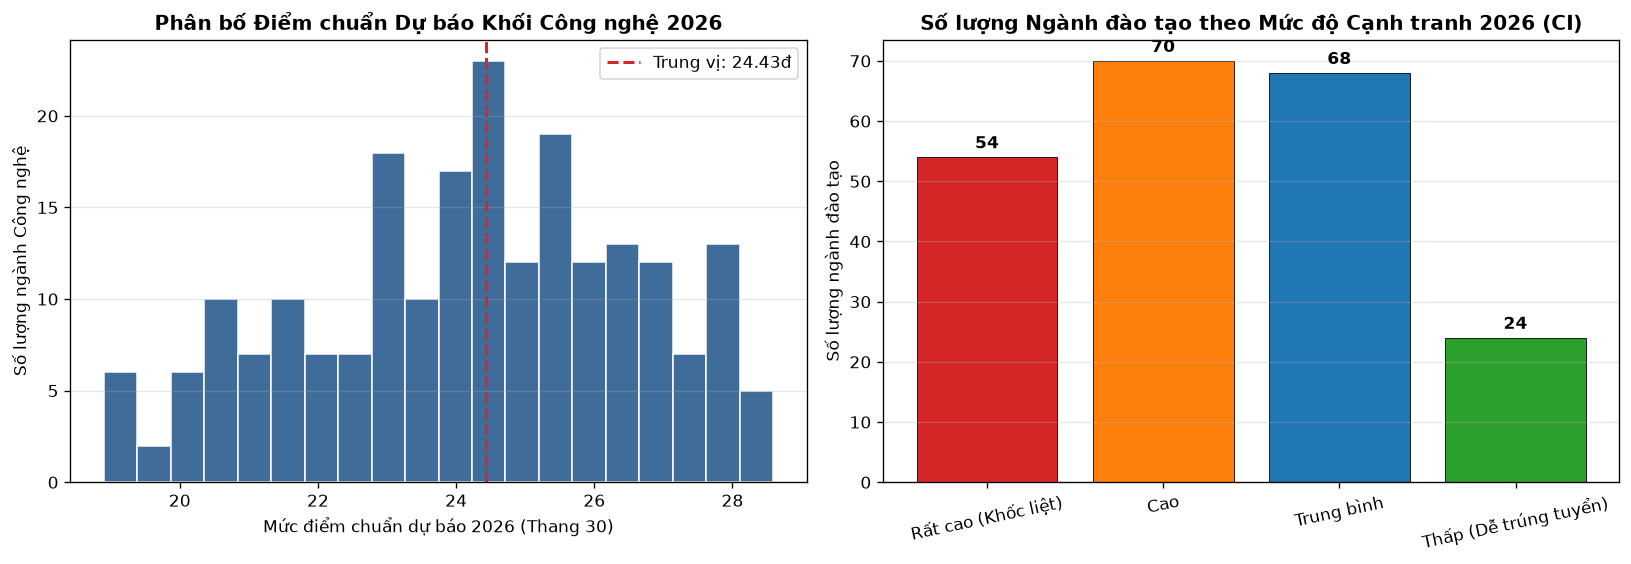

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13.8, 4.8), dpi=120)

axes[0].hist(filtered_df['diem_chuan_du_bao'], bins=20, color='#2b5c8f', edgecolor='white', alpha=0.9)
axes[0].axvline(filtered_df['diem_chuan_du_bao'].median(), color='#d62728', linestyle='--', linewidth=1.8, label=f"Trung vị: {filtered_df['diem_chuan_du_bao'].median():.2f}đ")
axes[0].set_title('Phân bố Điểm chuẩn Dự báo Khối Công nghệ 2026', fontweight='bold')
axes[0].set_xlabel('Mức điểm chuẩn dự báo 2026 (Thang 30)')
axes[0].set_ylabel('Số lượng ngành Công nghệ')
axes[0].grid(axis='y', alpha=0.3); axes[0].legend()

thu_tu_ct = ["Rất cao (Khốc liệt)", "Cao", "Trung bình", "Thấp (Dễ trúng tuyển)"]
dem_ct = [ct_rat_cao, ct_cao, ct_tb, ct_thap]
mau_ct = ['#d62728', '#ff7f0e', '#1f77b4', '#2ca02c']
bars = axes[1].bar(thu_tu_ct, dem_ct, color=mau_ct, edgecolor='black', linewidth=0.5)
axes[1].bar_label(bars, padding=3, fontweight='bold')
axes[1].set_title('Số lượng Ngành đào tạo theo Mức độ Cạnh tranh 2026 (CI)', fontweight='bold')
axes[1].set_ylabel('Số lượng ngành đào tạo')
axes[1].tick_params(axis='x', rotation=12)
axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Diễn giải thực tiễn bức tranh dự báo tuyển sinh Công nghệ 2026:**
- Phân bố điểm chuẩn dự báo năm 2026 của **216 chương trình Công nghệ – Kỹ thuật** tại Hà Nội trải rộng từ nhóm trường ứng dụng dưới `22,0 điểm` đến nhóm tinh hoa trên `26,5 điểm`, với mức trung vị toàn khối neo quanh ngưỡng khá giỏi (~`24,3 điểm`).
- Đánh giá theo **Chỉ số Cạnh tranh Đa biến (CI)**, có tới **124/216 ngành (57,4%)** nằm ở hai phân khúc **Cạnh tranh Rất cao (`54 ngành - 25,0%`)** và **Cạnh tranh Cao (`70 ngành - 32,4%`)**. Điều này chứng minh rằng khi tính thêm áp lực tỷ lệ chọi trên chỉ tiêu THPT thực tế và thương hiệu trường, sức nóng cạnh tranh không chỉ dồn ở các ngành điểm 27–29 mà còn lan sang cả các ngành điểm 25–26 có chỉ tiêu THPT bị thu hẹp.
- Ở chiều ngược lại, có **68 ngành Trung bình (`31,5%`)** và **24 ngành Thấp (`11,1%`)**, mở ra cơ hội trúng tuyển an toàn cho nhóm thí sinh phổ điểm khá nếu biết phân bổ nguyện vọng hợp lý qua Tab *Nhóm An Toàn* và *Nhóm Vừa Sức*.
- Xét về biến động so với năm 2025, có **120 ngành tăng nhẹ (`55,6%`)**, **56 ngành giảm điểm (`25,9%`)** và **40 ngành giữ ổn định (`18,5%`)**, phản ánh sự điều chỉnh phân hóa theo chỉ tiêu THPT thực tế của từng trường.

---
### 7.6. Cơ chế Khởi chạy Nhanh (`run.bat`), Đánh giá Công cụ Dashboard & Kết luận Dự án

**Đoạn code nhỏ kiểm tra tệp phím tắt `run.bat` và tính sẵn sàng của bộ tệp Offline trước khi lên trình bày:**

In [10]:
with open('run.bat', 'r', encoding='utf-8') as f:
    noi_dung_bat = f.read()

print("=== NỘI DUNG TỆP KHỞI CHẠY NHANH (run.bat) ===")
print(noi_dung_bat)
print("\n=== KIỂM TRA TRẠNG THÁI SẴN SÀNG DEMO OFFLINE ===")
for duong_dan in ['app.py', 'results/predictions_2026.csv', 'results/school_mapping.json', 'models/ultimate_model.pkl']:
    kich_thuoc_kb = os.path.getsize(duong_dan) / 1024
    print(f"  [SẴN SÀNG] {duong_dan:<32} ({kich_thuoc_kb:,.1f} KB)")

=== NỘI DUNG TỆP KHỞI CHẠY NHANH (run.bat) ===
@echo off
cd /d "%~dp0"

echo ==================================================
echo   KHOI DONG HE THONG DU BAO DIEM CHUAN DAI HOC 2026
echo ==================================================
echo.
echo Dang mo giao dien Web tren trinh duyet, vui long cho...

if exist "C:\Users\LENOVO\.local\bin\python3.15.exe" (
    "C:\Users\LENOVO\.local\bin\python3.15.exe" -m streamlit run app.py
) else (
    python -m streamlit run app.py
)

pause

=== KIỂM TRA TRẠNG THÁI SẴN SÀNG DEMO OFFLINE ===
  [SẴN SÀNG] app.py                           (12.2 KB)
  [SẴN SÀNG] results/predictions_2026.csv     (27.5 KB)
  [SẴN SÀNG] results/school_mapping.json      (1.6 KB)
  [SẴN SÀNG] models/ultimate_model.pkl        (1,831.4 KB)

#### 1. Đánh giá Việc Sử dụng `Streamlit` Xây dựng Dashboard Tư vấn Tuyển sinh

| Khía cạnh đánh giá | Phân tích chi tiết |
|---|---|
| **Ưu điểm nổi bật** | 1. **Đồng bộ 100% hệ sinh thái Python:** Kết nối trực tiếp với `pandas` và `plotly` mà không tốn thời gian viết giao diện HTML/CSS/JavaScript phức tạp, giúp nhóm tập trung tối đa vào chất lượng dữ liệu và mô hình.<br>2. **Tương tác tức thời (*Reactive UI*):** Ngay khi thí sinh tăng/giảm `0.1 điểm` hoặc đổi khối thi, toàn bộ 3 Tab nguyện vọng tự động tính toán và sắp xếp lại dưới `0.1 giây`.<br>3. **Kiến trúc Offline an toàn tuyệt đối khi bảo vệ:** Web App đọc trực tiếp từ 2 tệp kết quả nhẹ (`predictions_2026.csv` và `school_mapping.json`), không phụ thuộc mạng Internet hay dịch vụ SQL ngầm trong lúc demo trực tiếp trước hội đồng.<br>4. **Trực quan, đúng trọng tâm người dùng phổ thông:** Chuyển hóa sai số Học máy thành quy tắc 3 nhóm nguyện vọng (`±0.5 điểm`) rất gần gũi với tư duy đăng ký xét tuyển thực tế. |
| **Hạn chế tồn đọng** | 1. **Phạm vi phương thức xét tuyển:** Hệ thống hiện tập trung chuẩn hóa cho phương thức xét điểm thi tốt nghiệp THPT thang 30 tại khu vực Hà Nội, chưa tích hợp bảng quy đổi điểm Đánh giá năng lực (`HSA`), Đánh giá tư duy (`TSA`) hay chứng chỉ quốc tế.<br>2. **Cơ chế chạy lại kịch bản (*Full Script Rerun*):** Mặc định Streamlit chạy lại file từ đầu mỗi lần bấm lọc; hiện với 216 dòng thì cực mượt, nhưng nếu mở rộng lên hàng trăm nghìn dòng toàn quốc sẽ cần bổ sung bộ nhớ đệm `@st.cache_data`.<br>3. **Phạm vi triển khai:** Ứng dụng hiện khởi chạy cục bộ qua `run.bat` (`localhost:8501`), chưa đưa lên máy chủ công khai để nhiều người truy cập đồng thời qua điện thoại. |
| **Hướng phát triển** | Đóng gói ứng dụng lên **Streamlit Community Cloud** tích hợp `@st.cache_data`, bổ sung công cụ quy đổi điểm `HSA / TSA / IELTS` và mở rộng cơ sở dữ liệu sang khối trường Công nghệ tại TP.HCM và Đà Nẵng. |

---
#### 2. Tổng kết Khép kín Toàn bộ 6 Giai đoạn của Đồ án

| Giai đoạn | Hạng mục thực hiện | Thành quả định lượng đạt được |
|---|---|---|
| **Mở đầu (File 1)** | Xác lập bài toán & Khung nghiên cứu | Định nghĩa 3 câu hỏi nghiên cứu (RQ1–RQ3), tập trung vào 5 phân nhóm Công nghệ cốt lõi tại Hà Nội. |
| **Giai đoạn 1 (File 2)** | Kho dữ liệu SQL & Phổ điểm quốc gia | Xây dựng CSDL `ady` (**12 bảng chính thức**), nạp **4.292.528** thí sinh $\rightarrow$ tính **8.437.362** điểm tổ hợp $\rightarrow$ đóng gói vào bảng `ThongKePhoDiem_Cache` truy vấn tức thời. |
| **Giai đoạn 2 (File 3)** | Thu thập dữ liệu Web & Kiểm định DAMA | Cào tự động **13.368** dòng điểm chuẩn & tổng hợp **3.360** dòng chỉ tiêu; kiểm định 6 chiều chất lượng DAMA UK phát hiện 5 nhóm lỗi dữ liệu thô. |
| **Giai đoạn 3 (File 4)** | Làm sạch 2 tầng & Đồng bộ SQL | Nhân bản phổ điểm khối Tin học `A0T`/`D0T` sang `X06`/`X26`, quy đổi thang 40 $\rightarrow$ 30, khử trùng lặp cơ sở Bắc/Nam còn **13.120** dòng sạch, xuất từ điển 36 trường ĐH và khớp 242 tên ngành lệch bằng `difflib` ($\ge 90\%$). |
| **Giai đoạn 4 (File 5)** | Truy vấn SQL nâng cao & Kỹ thuật đặc trưng | Khai phá bằng `JOIN / CASE WHEN / CTE / LAG()`, chế tạo **16 đặc trưng chống rò rỉ tương lai** trên tập dữ liệu sạch **478 dòng** (0% giá trị khuyết). |
| **Giai đoạn 5 (File 6)** | Huấn luyện AI & Dự báo 2026 | Kiến trúc **3 Nhóm Chuyên gia `HistGradientBoostingRegressor` kép (`Direct + Delta`)** vượt xa `Linear Regression` nền, đạt **$R^2 = 0,735$** trên tập kiểm thử 2025 và xuất dự báo **216 ngành năm 2026** cùng Chỉ số Cạnh tranh Tuyển sinh $\text{CI}$. |
| **Giai đoạn 6 (File 7)** | Ứng dụng Web Tư vấn Tuyển sinh | Xây dựng Dashboard `Streamlit` (`app.py` + `run.bat`) phân 3 nhóm nguyện vọng (`An Toàn / Vừa Sức / Thử Thách`), sẵn sàng phục vụ tra cứu thực tế. |